# DEMO: DRRF Q3/2026 - Tính KPI sau khi áp dụng mô hình Ridge Rebate

File đầu vào được giả định đã có đầy đủ dữ liệu Q3/2026 (sau khi áp dụng) và nhóm Pilot/Đối chứng.


## Bước 0 - Import thư viện


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats


## Bước 1 - Đọc dữ liệu đã giả lập


In [16]:
# BƯỚC 0 - Thiết lập đường dẫn và đọc FILE ĐẦU VÀO ĐÃ GIẢ LẬP
from pathlib import Path

BASE = Path.home() / "Downloads"
OUT_DIR = BASE / "outputs"
CHART_DIR = OUT_DIR / "charts"
OUT_DIR.mkdir(parents=True, exist_ok=True)
CHART_DIR.mkdir(parents=True, exist_ok=True)

# File này đã chứa dữ liệu giả lập theo tháng, Pilot/Đối chứng và Q2/Q3
FILE_DAU_VAO = BASE / "DRRF_Q3_2026_full_KPI_simulated_monthly.csv"
FILE_THEO_NPP = OUT_DIR / "DRRF_Q3_2026_full_KPI_by_NPP.csv"
FILE_TONG_HOP_KPI = OUT_DIR / "DRRF_Q3_2026_full_KPI_summary.csv"
FILE_DID = OUT_DIR / "DRRF_Q3_2026_full_KPI_DiD.csv"

panel = pd.read_csv(FILE_DAU_VAO)
print(f"Đã đọc {len(panel):,} dòng, {panel.NPP_ID.nunique():,} NPP")
display(panel.head())


Đã đọc 1,440 dòng, 240 NPP


,NPP_ID,Thang,Tinh_Thanh,Vung_Mien,Loai_NPP,Nhom_thu_nghiem,Ky,Post_Q3,Su_kien_ngoai_le,Ly_do_churn,...,Net_Contribution_sau_rebate_VND,Bien_loi_nhuan_doi_thu_pct,Bien_loi_nhuan_NPP_sau_rebate_pct,Profitability_Gap_pct,Share_of_Wallet_pct,Active_Flag,Loss_Making_Flag,Ngan_sach_rebate_duyet_VND,Budget_Compliance_Ratio,Claim_Ratio
0,NPP_001,2026-04-01,Vĩnh Long,Tây Nam Bộ (ĐBSCL),Nhà phân phối cấp 1,Pilot,Q2_2026,0,Không,Không,...,3.749293e+07,9.313561,1.203516,-8.110045,54.203893,1,0,1.115275e+08,0.980813,1.000429
1,NPP_001,2026-05-01,Vĩnh Long,Tây Nam Bộ (ĐBSCL),Nhà phân phối cấp 1,Pilot,Q2_2026,0,Thiếu hàng,Không,...,4.252997e+07,9.548562,1.437283,-8.111279,52.460418,1,0,1.067226e+08,0.966016,0.985336
2,NPP_001,2026-06-01,Vĩnh Long,Tây Nam Bộ (ĐBSCL),Nhà phân phối cấp 1,Pilot,Q2_2026,0,Thiếu hàng,Không,...,4.818377e+07,9.529971,1.715146,-7.814825,53.460062,1,0,1.010593e+08,0.914284,0.932569
3,NPP_001,2026-07-01,Vĩnh Long,Tây Nam Bộ (ĐBSCL),Nhà phân phối cấp 1,Pilot,Q3_2026,1,Không,Không,...,5.933764e+07,9.702734,1.713494,-7.989240,54.790417,1,0,1.205534e+08,0.972209,0.962594
4,NPP_001,2026-08-01,Vĩnh Long,Tây Nam Bộ (ĐBSCL),Nhà phân phối cấp 1,Pilot,Q3_2026,1,Không,Không,...,6.306547e+07,9.715632,1.796212,-7.919420,55.926063,1,0,1.205534e+08,1.026629,0.996352


## Bước 2 - Khai báo hàm DiD và cấu hình biểu đồ


In [30]:
# BƯỚC 1 - Hàm Difference-in-Differences
def tinh_DiD(df, bien_so, ten_nhom="Nhom_thu_nghiem", ten_ky="Ky", ten_npp="NPP_ID"):
    bang_rong = df.pivot(index=[ten_npp, ten_nhom], columns=ten_ky, values=bien_so).reset_index()
    bang_rong["Thay_doi"] = bang_rong["Q3_2026"] - bang_rong["Q2_2026"]
    pilot = bang_rong.loc[bang_rong[ten_nhom].eq("Pilot"), "Thay_doi"]
    control = bang_rong.loc[bang_rong[ten_nhom].eq("Đối chứng"), "Thay_doi"]
    did = pilot.mean() - control.mean()
    se = np.sqrt(pilot.var(ddof=1)/len(pilot) + control.var(ddof=1)/len(control))
    dfree = len(pilot) + len(control) - 2
    p = 2 * stats.t.sf(abs(did/se), dfree)
    return {"KPI":bien_so,"Tac_dong_DiD":did,"Sai_so_chuan":se,"KTC95_Duoi":did-1.96*se,"KTC95_Tren":did+1.96*se,"Gia_tri_p":p,"Thay_doi_Pilot":pilot.mean(),"Thay_doi_Doi_chung":control.mean()}

MAU_ACCENT="2E74B5"; MAU_XANH_LA="2E8B57"; MAU_CAM="F39C12"; MAU_DO="C0392B"; MAU_TIM="8E44AD"
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 9, "axes.titlesize": 11})



In [14]:
def tinh_did(
    df,
    outcome,
    nhom_treatment,
    nhom_control,
    ky_truoc,
    ky_sau,
    nhom_col="Nhom_thu_nghiem",
    ky_col="Ky",
):
    """Tính Difference-in-Differences (DiD) từ trung bình của 4 nhóm-kỳ."""
    required_cols = [outcome, nhom_col, ky_col]
    missing_cols = [col for col in required_cols if col not in df.columns]
    if missing_cols:
        raise KeyError(f"Thiếu cột trong DataFrame: {missing_cols}")

    means = df.groupby([nhom_col, ky_col])[outcome].mean()

    cells = {
        "treatment_truoc": (nhom_treatment, ky_truoc),
        "treatment_sau": (nhom_treatment, ky_sau),
        "control_truoc": (nhom_control, ky_truoc),
        "control_sau": (nhom_control, ky_sau),
    }
    missing_cells = [name for name, key in cells.items() if key not in means.index]
    if missing_cells:
        raise ValueError(f"Không có dữ liệu cho các nhóm-kỳ: {missing_cells}")

    treatment_truoc = means[cells["treatment_truoc"]]
    treatment_sau = means[cells["treatment_sau"]]
    control_truoc = means[cells["control_truoc"]]
    control_sau = means[cells["control_sau"]]

    did = (treatment_sau - treatment_truoc) - (control_sau - control_truoc)

    return {
        "treatment_truoc": treatment_truoc,
        "treatment_sau": treatment_sau,
        "control_truoc": control_truoc,
        "control_sau": control_sau,
        "DID": did,
    }

## Bước 3 - Tổng hợp cấp NPP-Quý và tính thay đổi


In [20]:
# Run cells 4 and 7 before this cell.
# Tạo `tong_hop_quy` nếu chưa có trong notebook; tránh lỗi "undefined variable"
if "panel" not in globals():
    panel = pd.read_csv(FILE_DAU_VAO)

if "tong_hop_quy" not in globals():
    tong_hop_quy = (
        panel.groupby(["NPP_ID", "Nhom_thu_nghiem", "Ky"], as_index=False)
        .agg({
            "San_luong_tan": "sum",
            "Net_Contribution_sau_rebate_VND": "sum",
            "Rebate_thuc_chi_VND": "sum",
            "Ngan_sach_rebate_duyet_VND": "sum",
            "Profitability_Gap_pct": "mean",
            "Share_of_Wallet_pct": "mean",
            "Active_Flag": "last",
            "Loss_Making_Flag": "last",
        })
    )

tong_hop_quy["Budget_Compliance_Ratio"] = (
    tong_hop_quy["Rebate_thuc_chi_VND"]
    / tong_hop_quy["Ngan_sach_rebate_duyet_VND"].replace(0, np.nan)
)

# Chuyển từ dạng dài (long) sang dạng rộng (wide): mỗi NPP 1 dòng, có cả Q2 và Q3
bang_rong = tong_hop_quy.pivot(index=['NPP_ID', 'Nhom_thu_nghiem'], columns='Ky').reset_index()
theo_npp = pd.DataFrame({'NPP_ID': bang_rong.NPP_ID, 'Nhom_thu_nghiem': bang_rong.Nhom_thu_nghiem})

CAC_CHI_SO_THEO_NPP = [
    'San_luong_tan', 'Net_Contribution_sau_rebate_VND', 'Rebate_thuc_chi_VND', 'Profitability_Gap_pct',
    'Share_of_Wallet_pct', 'Active_Flag', 'Loss_Making_Flag', 'Budget_Compliance_Ratio',
]
for chi_so in CAC_CHI_SO_THEO_NPP:
    theo_npp[f'{chi_so}_Q2'] = bang_rong[(chi_so, 'Q2_2026')]
    theo_npp[f'{chi_so}_Q3'] = bang_rong[(chi_so, 'Q3_2026')]
    theo_npp[f'{chi_so}_Thay_doi'] = theo_npp[f'{chi_so}_Q3'] - theo_npp[f'{chi_so}_Q2']

theo_npp['Incremental_Volume_tan'] = theo_npp.San_luong_tan_Thay_doi
theo_npp['Incremental_Gross_Profit_VND'] = theo_npp.Net_Contribution_sau_rebate_VND_Thay_doi
theo_npp['Incremental_Rebate_Cost_VND'] = theo_npp.Rebate_thuc_chi_VND_Thay_doi
theo_npp['Rebate_ROI'] = np.where(
    theo_npp.Incremental_Rebate_Cost_VND > 0,
    theo_npp.Incremental_Gross_Profit_VND / theo_npp.Incremental_Rebate_Cost_VND,
    np.nan,
)
theo_npp['Co_duy_tri_Q3'] = theo_npp.Active_Flag_Q3
theo_npp['Co_roi_bo_Q3'] = 1 - theo_npp.Active_Flag_Q3
theo_npp['Tuan_thu_ngan_sach_Q3'] = (theo_npp.Budget_Compliance_Ratio_Q3 <= 1).astype(int)
theo_npp['Thua_lo_Q3'] = theo_npp.Loss_Making_Flag_Q3.astype(int)
theo_npp.to_csv(FILE_THEO_NPP, index=False, encoding='utf-8-sig')

#---------------

print(f"Đã tổng hợp {len(theo_npp):,} NPP.")
print("Các chỉ số theo NPP:", ", ".join(CAC_CHI_SO_THEO_NPP))
display(theo_npp.head())

Đã tổng hợp 240 NPP.
Các chỉ số theo NPP: San_luong_tan, Net_Contribution_sau_rebate_VND, Rebate_thuc_chi_VND, Profitability_Gap_pct, Share_of_Wallet_pct, Active_Flag, Loss_Making_Flag, Budget_Compliance_Ratio


,NPP_ID,Nhom_thu_nghiem,San_luong_tan_Q2,San_luong_tan_Q3,San_luong_tan_Thay_doi,Net_Contribution_sau_rebate_VND_Q2,Net_Contribution_sau_rebate_VND_Q3,Net_Contribution_sau_rebate_VND_Thay_doi,Rebate_thuc_chi_VND_Q2,Rebate_thuc_chi_VND_Q3,...,Budget_Compliance_Ratio_Q3,Budget_Compliance_Ratio_Thay_doi,Incremental_Volume_tan,Incremental_Gross_Profit_VND,Incremental_Rebate_Cost_VND,Rebate_ROI,Co_duy_tri_Q3,Co_roi_bo_Q3,Tuan_thu_ngan_sach_Q3,Thua_lo_Q3
0,NPP_001,Pilot,5797.191473,7041.112932,1243.921459,1.282067e+08,2.017231e+08,7.351643e+07,3.048801e+08,3.719048e+08,...,1.028327,0.073516,1243.921459,7.351643e+07,6.702469e+07,1.096856,1,0,0,0
1,NPP_002,Đối chứng,5257.241455,5638.234139,380.992683,3.355676e+08,3.595084e+08,2.394081e+07,2.361138e+08,2.517135e+08,...,0.963365,0.006159,380.992683,2.394081e+07,1.559975e+07,1.534692,1,0,1,0
2,NPP_003,Pilot,6435.569860,6805.401934,369.832074,7.429964e+08,8.923671e+08,1.493708e+08,3.940962e+08,3.098093e+08,...,0.999588,0.046628,369.832074,1.493708e+08,-8.428682e+07,NaN,1,0,1,0
3,NPP_004,Đối chứng,4775.036725,4919.970938,144.934213,6.426918e+08,6.456498e+08,2.957945e+06,2.171393e+08,2.275429e+08,...,0.989894,0.041336,144.934213,2.957945e+06,1.040359e+07,0.284320,1,0,1,0
4,NPP_005,Đối chứng,10756.387809,11163.745194,407.357385,4.668687e+08,4.481332e+08,-1.873553e+07,7.155946e+08,7.283073e+08,...,0.904484,-0.054677,407.357385,-1.873553e+07,1.271278e+07,-1.473755,1,0,1,0


## Bước 4 - Tính DiD và tổng hợp KPI


In [21]:
from pathlib import Path

CAC_BIEN_CAN_TINH_DID = [
    'San_luong_tan', 'Net_Contribution_sau_rebate_VND', 'Rebate_thuc_chi_VND', 'Profitability_Gap_pct',
    'Share_of_Wallet_pct', 'Budget_Compliance_Ratio', 'Loss_Making_Flag',
]
# Tổng hợp dữ liệu tháng thành một dòng cho mỗi NPP-quý.
# Run cell 2 first so pd is defined.
group_cols = ["NPP_ID", "Nhom_thu_nghiem", "Ky"]

if "panel" not in globals():

    FILE_DAU_VAO = Path.home() / "Downloads" / "DRRF_Q3_2026_full_KPI_simulated_monthly.csv"
    panel = pd.read_csv(FILE_DAU_VAO)

tong_hop_quy = (
    panel.groupby(group_cols, as_index=False)
    .agg({
        "San_luong_tan": "sum",
        "Net_Contribution_sau_rebate_VND": "sum",
        "Rebate_thuc_chi_VND": "sum",
        "Ngan_sach_rebate_duyet_VND": "sum",
        "Profitability_Gap_pct": "mean",
        "Share_of_Wallet_pct": "mean",
        "Active_Flag": "last",
        "Loss_Making_Flag": "last",
    })
)

tong_hop_quy["Budget_Compliance_Ratio"] = (
    tong_hop_quy["Rebate_thuc_chi_VND"]
    / tong_hop_quy["Ngan_sach_rebate_duyet_VND"].replace(0, np.nan)
)

bang_DiD = pd.DataFrame([
    tinh_DiD(tong_hop_quy, bien)
    for bien in CAC_BIEN_CAN_TINH_DID
])
bang_DiD.to_csv(FILE_DID, index=False, encoding='utf-8-sig')
tra_DiD = bang_DiD.set_index('KPI')

nhom_pilot = theo_npp[theo_npp.Nhom_thu_nghiem.eq('Pilot')]
nhom_doi_chung = theo_npp[theo_npp.Nhom_thu_nghiem.eq('Đối chứng')]

sl_tang_them = tra_DiD.loc['San_luong_tan', 'Tac_dong_DiD']
lntt_tang_them = tra_DiD.loc['Net_Contribution_sau_rebate_VND', 'Tac_dong_DiD']
rebate_tang_them = tra_DiD.loc['Rebate_thuc_chi_VND', 'Tac_dong_DiD']

# ROI chỉ có ý nghĩa kinh tế khi chi phí rebate tăng thêm > 0 (đầu tư thêm).
# Khi chi phí rebate giảm (<0) nhưng lợi nhuận vẫn tăng, đây là trường hợp
# "tiết kiệm & tăng trưởng" (save-and-grow), không phải ROI đầu tư truyền thống.
if rebate_tang_them != 0:
    ty_le_hieu_qua = lntt_tang_them / abs(rebate_tang_them)
else:
    ty_le_hieu_qua = np.nan
che_do_hieu_qua = 'Hiệu quả đầu tư (Investment ROI)' if rebate_tang_them > 0 else 'Tiết kiệm & tăng trưởng (Save-and-grow)'

bang_tong_hop = [
    ['Incremental Volume (Sản lượng tăng thêm)', sl_tang_them, 'tấn/NPP/quý',
     'DiD sản lượng: Pilot - Đối chứng', 'Dương'],
    ['Incremental Gross Profit (Lợi nhuận gộp tăng thêm)', lntt_tang_them, 'VNĐ/NPP/quý',
     'DiD Net Contribution sau rebate', 'Dương'],
    ['Incremental Rebate Cost (Chi phí rebate tăng thêm)', rebate_tang_them, 'VNĐ/NPP/quý',
     'DiD rebate thực chi', 'Dùng làm mẫu số tính ROI'],
    ['Rebate ROI / Save-and-grow (Hiệu quả rebate)', ty_le_hieu_qua, 'lần',
     'Lợi nhuận gộp tăng thêm / |Chi phí rebate tăng thêm|', che_do_hieu_qua],
    ['Profitability Gap (Chênh lệch biên lợi nhuận)', tra_DiD.loc['Profitability_Gap_pct', 'Tac_dong_DiD'],
     'điểm %', 'DiD (biên NPP sau rebate) - (biên đối thủ)', 'Cải thiện'],
    ['Share of Wallet (Tỷ trọng trong danh mục NPP)', tra_DiD.loc['Share_of_Wallet_pct', 'Tac_dong_DiD'],
     'điểm %', 'DiD Share of Wallet', 'Cải thiện'],
    ['Retention - Pilot (Tỷ lệ duy trì)', nhom_pilot.Co_duy_tri_Q3.mean(), '%',
     'Số NPP còn hoạt động cuối Q3 / Tổng NPP đầu Q3', 'Không giảm'],
    ['Retention - Đối chứng (Tỷ lệ duy trì)', nhom_doi_chung.Co_duy_tri_Q3.mean(), '%',
     'Số NPP còn hoạt động cuối Q3 / Tổng NPP đầu Q3', 'So sánh đối chiếu'],
    ['Churn - Pilot (Tỷ lệ rời bỏ)', nhom_pilot.Co_roi_bo_Q3.mean(), '%',
     '1 - Tỷ lệ duy trì', 'Không tăng'],
    ['Budget Compliance - Pilot (Tỷ lệ tuân thủ ngân sách)', nhom_pilot.Tuan_thu_ngan_sach_Q3.mean(), '%',
     'Số NPP có rebate thực chi <= ngân sách duyệt', '>= 95% số NPP'],
    ['Budget Utilization - Pilot (Mức sử dụng ngân sách)', nhom_pilot.Budget_Compliance_Ratio_Q3.mean(), '%',
     'Rebate thực chi / Ngân sách được duyệt', '<= 100%'],
    ['Loss-making NPP Rate - Pilot (Tỷ lệ NPP thua lỗ)', nhom_pilot.Thua_lo_Q3.mean(), '%',
     'Số NPP có Net Contribution < 0', 'Không tăng'],
    ['Loss-making NPP Rate - Đối chứng (Tỷ lệ NPP thua lỗ)', nhom_doi_chung.Thua_lo_Q3.mean(), '%',
     'Số NPP có Net Contribution < 0', 'So sánh đối chiếu'],
]
bang_KPI = pd.DataFrame(bang_tong_hop, columns=['KPI', 'Ket_qua', 'Don_vi', 'Cong_thuc', 'Nguong_danh_gia'])
bang_KPI.to_csv(FILE_TONG_HOP_KPI, index=False, encoding='utf-8-sig')

print(bang_KPI)


                                                  KPI       Ket_qua  \
0            Incremental Volume (Sản lượng tăng thêm)  1.701990e+02   
1   Incremental Gross Profit (Lợi nhuận gộp tăng t...  6.879619e+07   
2   Incremental Rebate Cost (Chi phí rebate tăng t... -3.772492e+06   
3        Rebate ROI / Save-and-grow (Hiệu quả rebate)  1.823627e+01   
4       Profitability Gap (Chênh lệch biên lợi nhuận)  3.570995e-01   
5       Share of Wallet (Tỷ trọng trong danh mục NPP)  1.697621e+00   
6                   Retention - Pilot (Tỷ lệ duy trì)  9.666667e-01   
7               Retention - Đối chứng (Tỷ lệ duy trì)  9.583333e-01   
8                        Churn - Pilot (Tỷ lệ rời bỏ)  3.333333e-02   
9   Budget Compliance - Pilot (Tỷ lệ tuân thủ ngân...  7.583333e-01   
10  Budget Utilization - Pilot (Mức sử dụng ngân s...  9.862955e-01   
11   Loss-making NPP Rate - Pilot (Tỷ lệ NPP thua lỗ)  5.833333e-02   
12  Loss-making NPP Rate - Đối chứng (Tỷ lệ NPP th...  3.333333e-02   

     

In [ ]:
# Print kết quả KPI và theo NPP nếu các biến đã được tính toán
from IPython.display import display, Image
import pandas as pd

print("=== KẾT QUẢ KPI ===")
if "bang_KPI" in globals():
    display(bang_KPI)
else:
    print("Chưa có biến bang_KPI. Hãy chạy cell tính KPI trước.")

if "theo_npp" in globals():
    print("\n=== KẾT QUẢ THEO NPP ===")
    display(theo_npp)



=== KẾT QUẢ KPI ===


,KPI,Ket_qua,Don_vi,Cong_thuc,Nguong_danh_gia
0,Incremental Volume (Sản lượng tăng thêm),1.701990e+02,tấn/NPP/quý,DiD sản lượng: Pilot - Đối chứng,Dương
1,Incremental Gross Profit (Lợi nhuận gộp tăng t...,6.879619e+07,VNĐ/NPP/quý,DiD Net Contribution sau rebate,Dương
2,Incremental Rebate Cost (Chi phí rebate tăng t...,-3.772492e+06,VNĐ/NPP/quý,DiD rebate thực chi,Dùng làm mẫu số tính ROI
3,Rebate ROI / Save-and-grow (Hiệu quả rebate),1.823627e+01,lần,Lợi nhuận gộp tăng thêm / |Chi phí rebate tăng...,Tiết kiệm & tăng trưởng (Save-and-grow)
4,Profitability Gap (Chênh lệch biên lợi nhuận),3.570995e-01,điểm %,DiD (biên NPP sau rebate) - (biên đối thủ),Cải thiện
5,Share of Wallet (Tỷ trọng trong danh mục NPP),1.697621e+00,điểm %,DiD Share of Wallet,Cải thiện
6,Retention - Pilot (Tỷ lệ duy trì),9.666667e-01,%,Số NPP còn hoạt động cuối Q3 / Tổng NPP đầu Q3,Không giảm
7,Retention - Đối chứng (Tỷ lệ duy trì),9.583333e-01,%,Số NPP còn hoạt động cuối Q3 / Tổng NPP đầu Q3,So sánh đối chiếu
8,Churn - Pilot (Tỷ lệ rời bỏ),3.333333e-02,%,1 - Tỷ lệ duy trì,Không tăng
9,Budget Compliance - Pilot (Tỷ lệ tuân thủ ngân...,7.583333e-01,%,Số NPP có rebate thực chi <= ngân sách duyệt,>= 95% số NPP



=== KẾT QUẢ THEO NPP ===


,NPP_ID,Nhom_thu_nghiem,San_luong_tan_Q2,San_luong_tan_Q3,San_luong_tan_Thay_doi,Net_Contribution_sau_rebate_VND_Q2,Net_Contribution_sau_rebate_VND_Q3,Net_Contribution_sau_rebate_VND_Thay_doi,Rebate_thuc_chi_VND_Q2,Rebate_thuc_chi_VND_Q3,...,Budget_Compliance_Ratio_Q3,Budget_Compliance_Ratio_Thay_doi,Incremental_Volume_tan,Incremental_Gross_Profit_VND,Incremental_Rebate_Cost_VND,Rebate_ROI,Co_duy_tri_Q3,Co_roi_bo_Q3,Tuan_thu_ngan_sach_Q3,Thua_lo_Q3
0,NPP_001,Pilot,5797.191473,7041.112932,1243.921459,1.282067e+08,2.017231e+08,7.351643e+07,3.048801e+08,3.719048e+08,...,1.028327,0.073516,1243.921459,7.351643e+07,6.702469e+07,1.096856,1,0,0,0
1,NPP_002,Đối chứng,5257.241455,5638.234139,380.992683,3.355676e+08,3.595084e+08,2.394081e+07,2.361138e+08,2.517135e+08,...,0.963365,0.006159,380.992683,2.394081e+07,1.559975e+07,1.534692,1,0,1,0
2,NPP_003,Pilot,6435.569860,6805.401934,369.832074,7.429964e+08,8.923671e+08,1.493708e+08,3.940962e+08,3.098093e+08,...,0.999588,0.046628,369.832074,1.493708e+08,-8.428682e+07,NaN,1,0,1,0
3,NPP_004,Đối chứng,4775.036725,4919.970938,144.934213,6.426918e+08,6.456498e+08,2.957945e+06,2.171393e+08,2.275429e+08,...,0.989894,0.041336,144.934213,2.957945e+06,1.040359e+07,0.284320,1,0,1,0
4,NPP_005,Đối chứng,10756.387809,11163.745194,407.357385,4.668687e+08,4.481332e+08,-1.873553e+07,7.155946e+08,7.283073e+08,...,0.904484,-0.054677,407.357385,-1.873553e+07,1.271278e+07,-1.473755,1,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
235,NPP_236,Đối chứng,3973.352675,4108.622735,135.270059,5.938091e+08,6.179563e+08,2.414717e+07,1.534530e+08,1.550991e+08,...,0.928360,-0.042494,135.270059,2.414717e+07,1.646031e+06,14.669938,1,0,1,0
236,NPP_237,Pilot,1577.510444,1665.988997,88.478553,8.162856e+07,4.993008e+07,-3.169848e+07,2.944063e+07,8.087032e+07,...,1.014738,0.099899,88.478553,-3.169848e+07,5.142969e+07,-0.616346,1,0,0,0
237,NPP_238,Pilot,5794.233009,6035.833392,241.600384,7.799402e+08,9.694182e+08,1.894779e+08,3.302261e+08,2.350859e+08,...,0.963221,0.016192,241.600384,1.894779e+08,-9.514023e+07,NaN,1,0,1,0
238,NPP_239,Pilot,7718.517053,8414.848652,696.331599,3.424906e+08,4.948796e+08,1.523889e+08,4.838643e+08,4.624048e+08,...,0.979777,0.019471,696.331599,1.523889e+08,-2.145957e+07,NaN,1,0,1,0


## Bước 5 - Trực quan hóa kết quả


In [32]:
# --- Biểu đồ 1: Tác động DiD của 4 KPI trọng yếu, kèm khoảng tin cậy 95% ---
cac_kpi_chinh = [
    ('San_luong_tan', 'Incremental Volume', 'tấn/NPP/quý', 1, '#1f77b4'),
    ('Net_Contribution_sau_rebate_VND', 'Incremental Gross Profit', 'triệu VNĐ/NPP/quý', 1e6, '#' + MAU_XANH_LA),
    ('Profitability_Gap_pct', 'Profitability Gap', 'điểm %', 1, '#d35400'),
    ('Share_of_Wallet_pct', 'Share of Wallet', 'điểm %', 1, '#' + MAU_TIM),
]
fig, axs = plt.subplots(2, 2, figsize=(9, 6.5))
for ax, (bien, ten, dvt, ty_le, mau) in zip(axs.ravel(), cac_kpi_chinh):
    hang = tra_DiD.loc[bien]
    gt = hang.Tac_dong_DiD / ty_le
    duoi = hang.KTC95_Duoi / ty_le
    tren = hang.KTC95_Tren / ty_le
    ax.errorbar([0], [gt], yerr=[[gt - duoi], [tren - gt]], fmt='o', markersize=8, capsize=7,
                color=mau, elinewidth=2)
    ax.axhline(0, color='grey', lw=1)
    ax.set_xticks([])
    ax.set_title(ten)
    ax.set_ylabel(dvt)
    ax.text(0, gt + (tren - duoi) * 0.12, f'{gt:+.2f}', ha='center', fontweight='bold', color=mau)
    ax.grid(axis='y', alpha=0.25)
fig.suptitle('Tác động thuần theo Difference-in-Differences - Q3/2026 (giả lập)', fontweight='bold')
plt.tight_layout()
plt.savefig(CHART_DIR / 'kpi_did.png', dpi=200)
plt.close()

# --- Biểu đồ 2: Lợi nhuận/chi phí tăng thêm và tỷ lệ hiệu quả rebate ---
fig, axs = plt.subplots(1, 2, figsize=(9, 4.2))
axs[0].bar(['Lợi nhuận gộp\ntăng thêm', 'Chi phí rebate\ntăng thêm'],
           [lntt_tang_them / 1e6, rebate_tang_them / 1e6], color=['#' + MAU_XANH_LA, '#' + MAU_CAM])
axs[0].set_ylabel('Triệu VNĐ/NPP/quý')
axs[0].set_title('Lợi ích và chi phí tăng thêm')
for i, v in enumerate([lntt_tang_them / 1e6, rebate_tang_them / 1e6]):
    axs[0].text(i, v + (max(abs(lntt_tang_them), abs(rebate_tang_them)) / 1e6) * 0.04, f'{v:.2f}',
                ha='center', fontweight='bold')
axs[1].bar(['ROI / Save-and-grow'], [ty_le_hieu_qua], color='#' + MAU_ACCENT)
axs[1].axhline(1, color='#' + MAU_DO, ls='--', label='Ngưỡng minh họa 1,0x')
axs[1].set_ylabel('Lần')
axs[1].set_title('Hiệu quả đầu tư rebate (ROI / Save-and-grow)')
axs[1].text(0, ty_le_hieu_qua + 0.05, f'{ty_le_hieu_qua:.2f}x', ha='center', fontweight='bold')
axs[1].legend()
plt.tight_layout()
plt.savefig(CHART_DIR / 'roi.png', dpi=200)
plt.close()

# --- Biểu đồ 3: Retention, Churn, Loss-making NPP Rate ---
nhan_truc = ['Retention', 'Churn', 'Loss-making']
gt_pilot = [nhom_pilot.Co_duy_tri_Q3.mean() * 100, nhom_pilot.Co_roi_bo_Q3.mean() * 100,
            nhom_pilot.Thua_lo_Q3.mean() * 100]
gt_doi_chung = [nhom_doi_chung.Co_duy_tri_Q3.mean() * 100, nhom_doi_chung.Co_roi_bo_Q3.mean() * 100,
                nhom_doi_chung.Thua_lo_Q3.mean() * 100]
x = np.arange(3)
do_rong = 0.36
plt.figure(figsize=(8, 4.5))
plt.bar(x - do_rong / 2, gt_pilot, do_rong, label='Pilot', color='#' + MAU_XANH_LA)
plt.bar(x + do_rong / 2, gt_doi_chung, do_rong, label='Đối chứng', color='#' + MAU_CAM)
plt.xticks(x, nhan_truc)
plt.ylabel('% số NPP')
plt.title('Retention, Churn và Loss-making NPP Rate')
plt.legend()
for i, v in enumerate(gt_pilot):
    plt.text(i - do_rong / 2, v + 0.7, f'{v:.1f}%', ha='center', fontsize=8)
for i, v in enumerate(gt_doi_chung):
    plt.text(i + do_rong / 2, v + 0.7, f'{v:.1f}%', ha='center', fontsize=8)
plt.tight_layout()
plt.savefig(CHART_DIR / 'risk.png', dpi=200)
plt.close()

# --- Biểu đồ 4: Phân phối mức sử dụng ngân sách rebate ---
pilot_pct_ns = nhom_pilot.Budget_Compliance_Ratio_Q3 * 100
doi_chung_pct_ns = nhom_doi_chung.Budget_Compliance_Ratio_Q3 * 100
plt.figure(figsize=(8, 4.6))
plt.hist(pilot_pct_ns, bins=15, alpha=0.65, label='Pilot', color='#1f77b4')
plt.hist(doi_chung_pct_ns, bins=15, alpha=0.55, label='Đối chứng', color='#' + MAU_CAM)
plt.axvline(100, color='#' + MAU_DO, ls='--', label='Trần ngân sách 100%')
plt.xlabel('Mức sử dụng ngân sách (%)')
plt.ylabel('Số NPP')
plt.title('Phân phối mức sử dụng ngân sách rebate Q3/2026')
plt.legend()
plt.tight_layout()
plt.savefig(CHART_DIR / 'budget_compliance.png', dpi=200)
plt.close()

# --- Biểu đồ 5: Profitability Gap và Share of Wallet trước-sau ---
bang_truoc_sau = tong_hop_quy.groupby(['Nhom_thu_nghiem', 'Ky']).agg(
    Profitability_Gap_pct=('Profitability_Gap_pct', 'mean'),
    Share_of_Wallet_pct=('Share_of_Wallet_pct', 'mean'),
).reset_index()
fig, axs = plt.subplots(1, 2, figsize=(9, 4.2))
for nhom, mau in [('Pilot', '#1f77b4'), ('Đối chứng', '#' + MAU_CAM)]:
    z = bang_truoc_sau[bang_truoc_sau.Nhom_thu_nghiem.eq(nhom)].set_index('Ky')
    axs[0].plot(['Q2', 'Q3'], [z.loc['Q2_2026', 'Profitability_Gap_pct'], z.loc['Q3_2026', 'Profitability_Gap_pct']],
                marker='o', label=nhom, color=mau)
    axs[1].plot(['Q2', 'Q3'], [z.loc['Q2_2026', 'Share_of_Wallet_pct'], z.loc['Q3_2026', 'Share_of_Wallet_pct']],
                marker='o', label=nhom, color=mau)
axs[0].axhline(0, color='grey', lw=1)
axs[0].set_title('Profitability Gap bình quân')
axs[0].set_ylabel('Điểm %')
axs[1].set_title('Share of Wallet bình quân')
axs[1].set_ylabel('%')
axs[1].legend()
plt.tight_layout()
plt.savefig(CHART_DIR / 'pg_sow.png', dpi=200)
plt.close()




In [31]:
fig.tight_layout()

# Lưu hình vào thư mục charts
file_hinh = CHART_DIR / "profitability_gap_share_wallet.png"
fig.savefig(file_hinh, dpi=200, bbox_inches="tight")

# Hiển thị hình ngay bên dưới cell trong notebook
plt.show()

print(f"Đã lưu biểu đồ tại: {file_hinh}")

Đã lưu biểu đồ tại: C:\Users\QUOC ANH\Downloads\outputs\charts\profitability_gap_share_wallet.png



=== BIỂU ĐỒ ===
budget_compliance.png


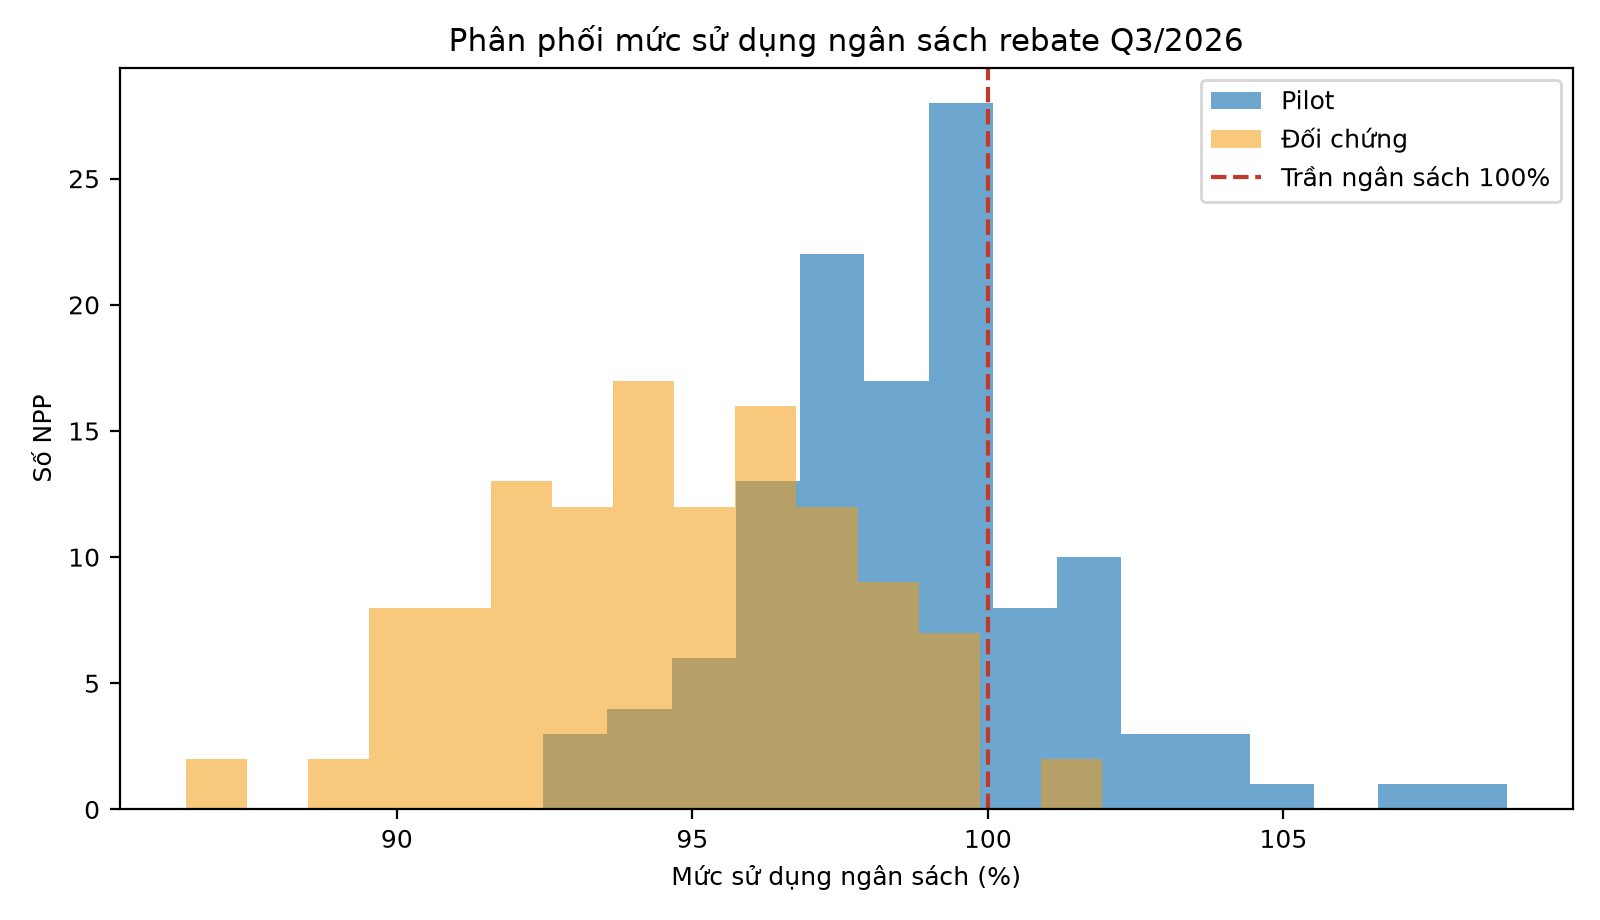

kpi_did.png


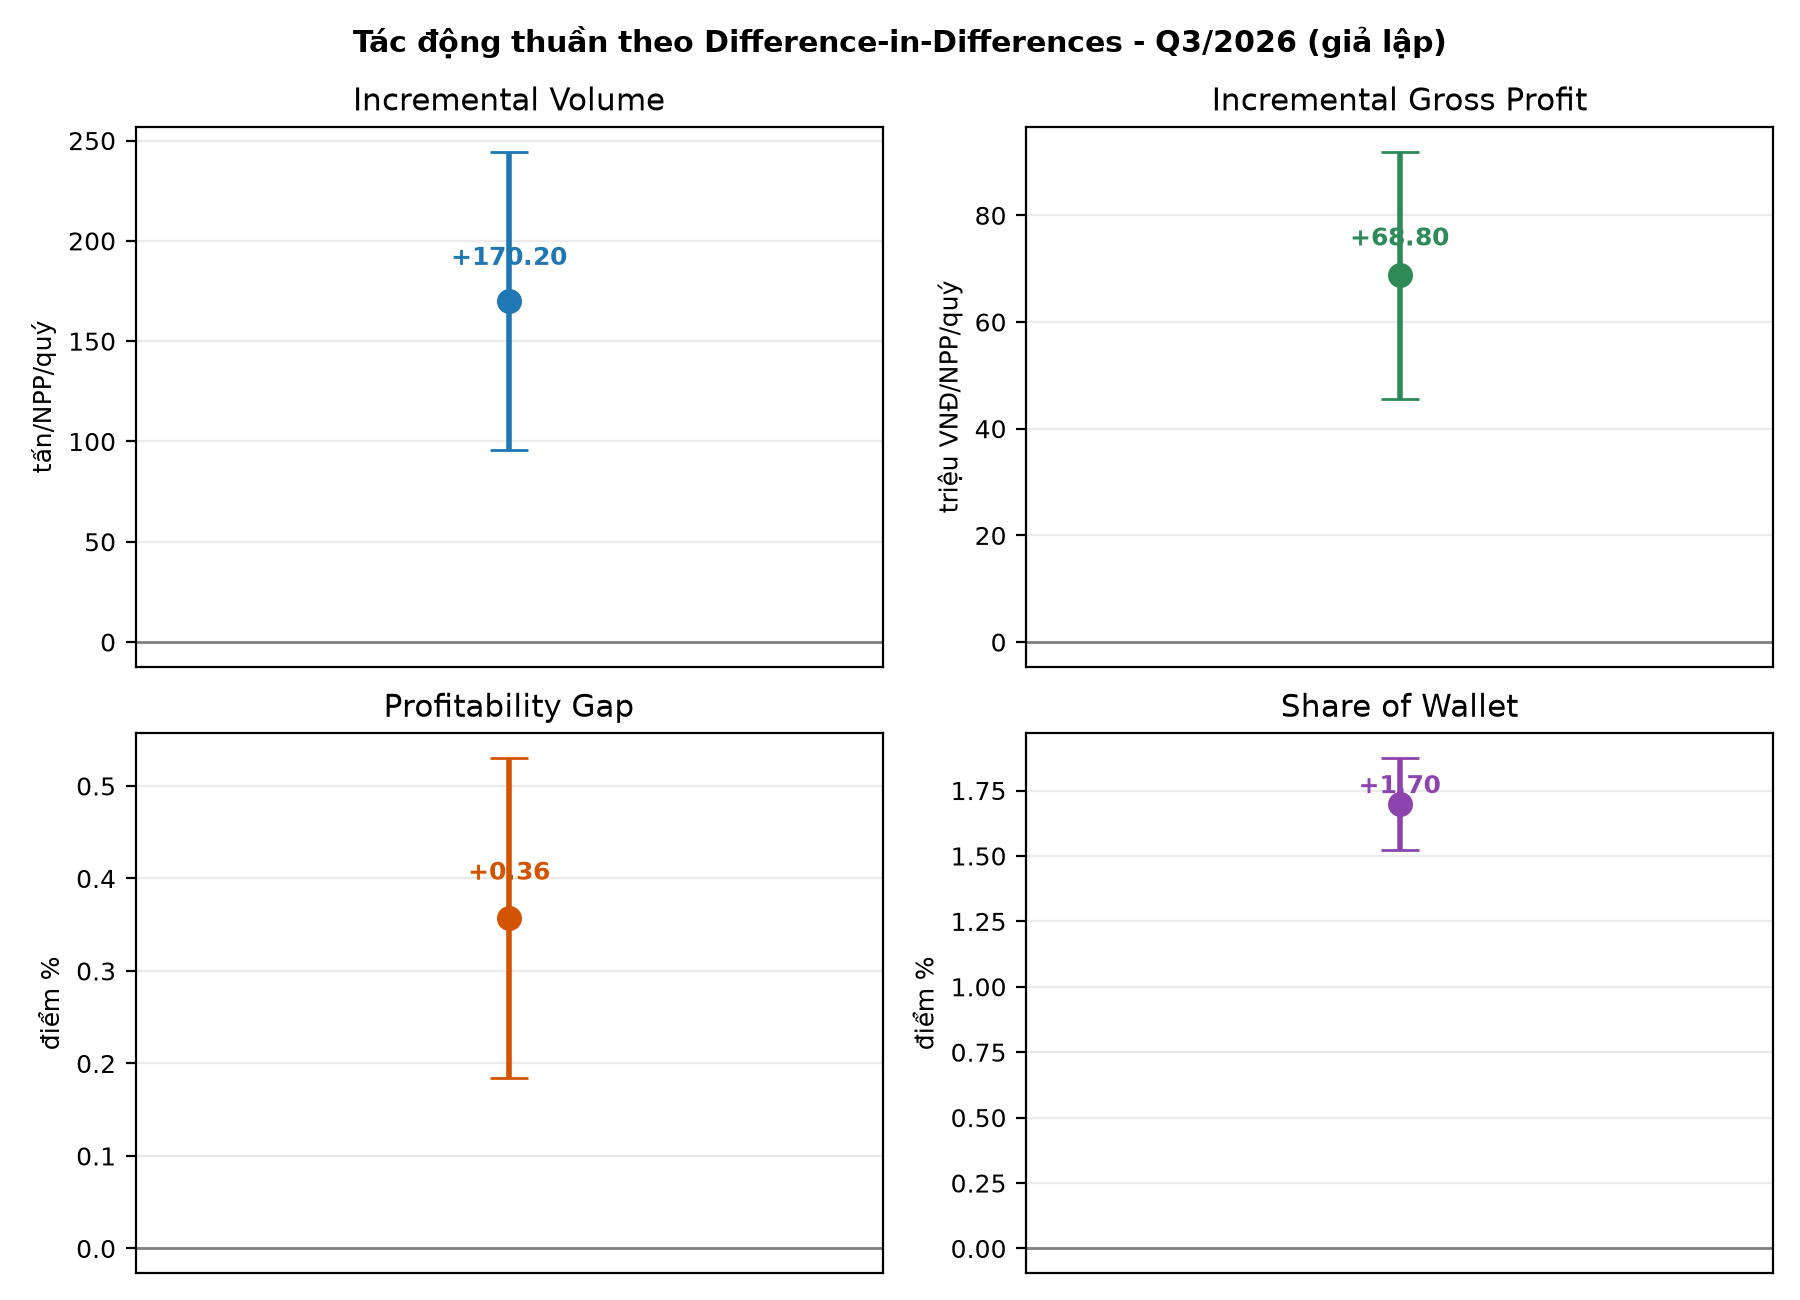

pg_sow.png


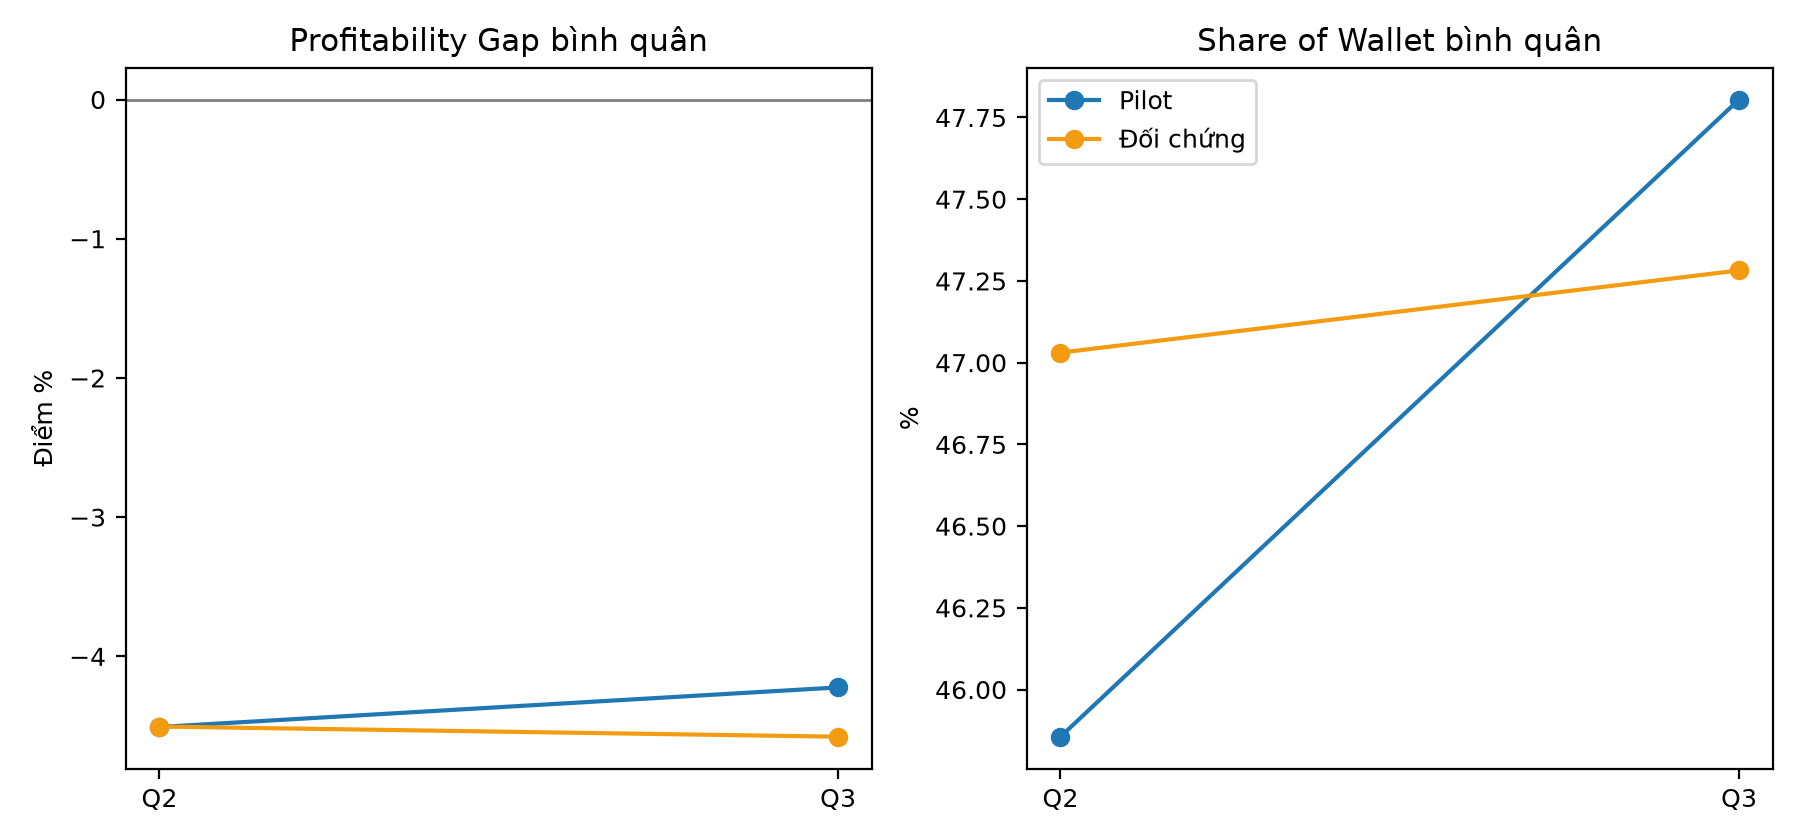

profitability_gap_share_wallet.png


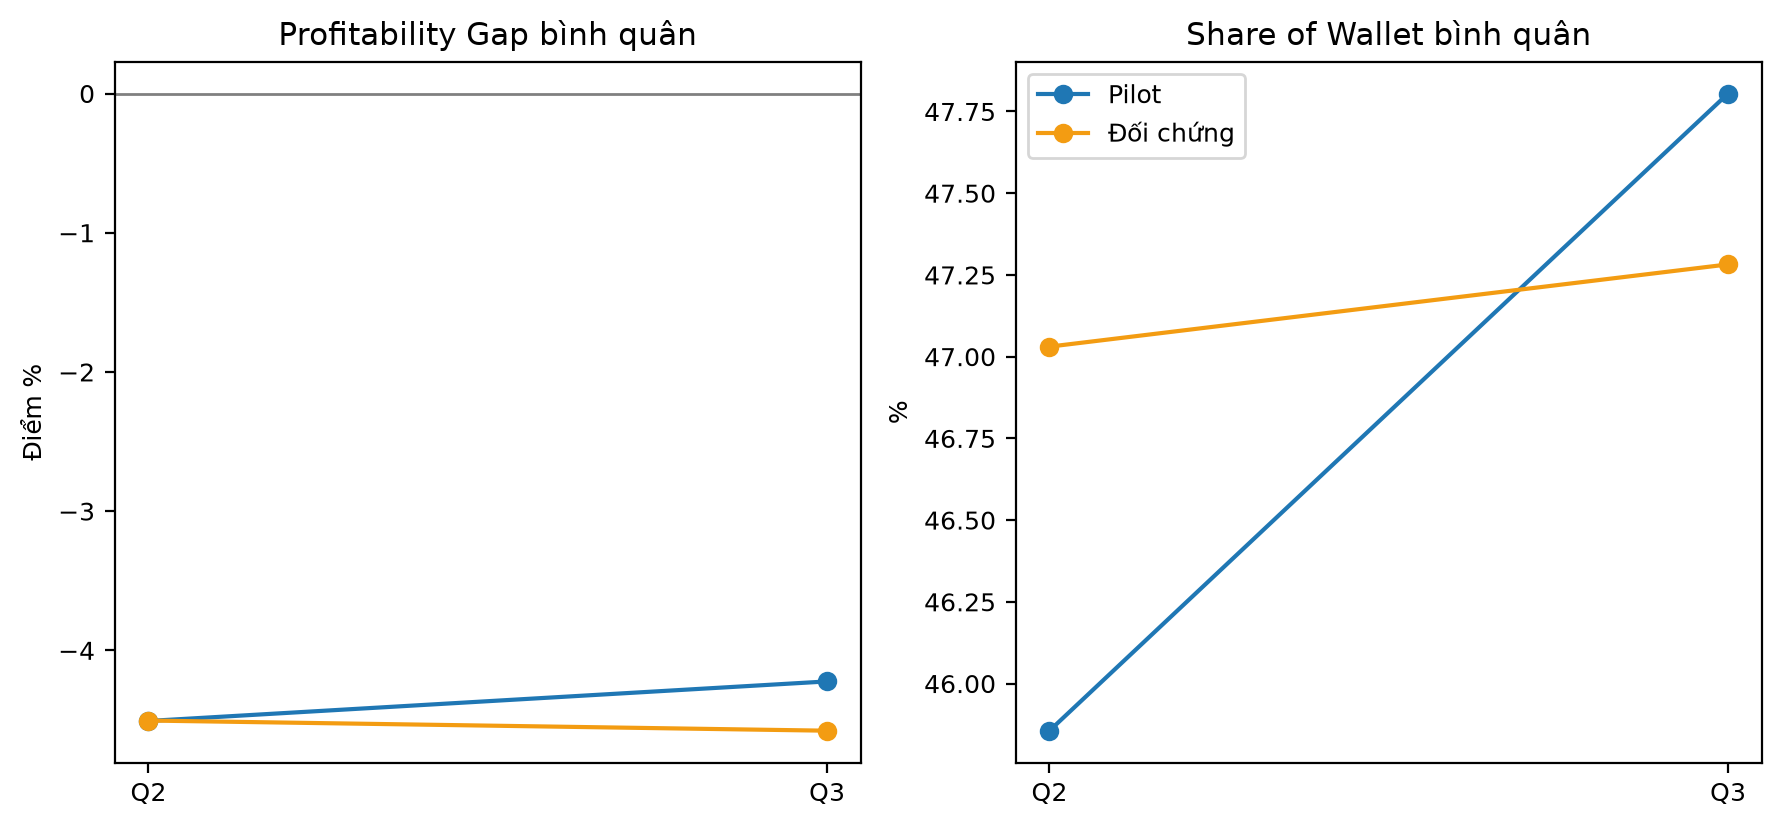

risk.png


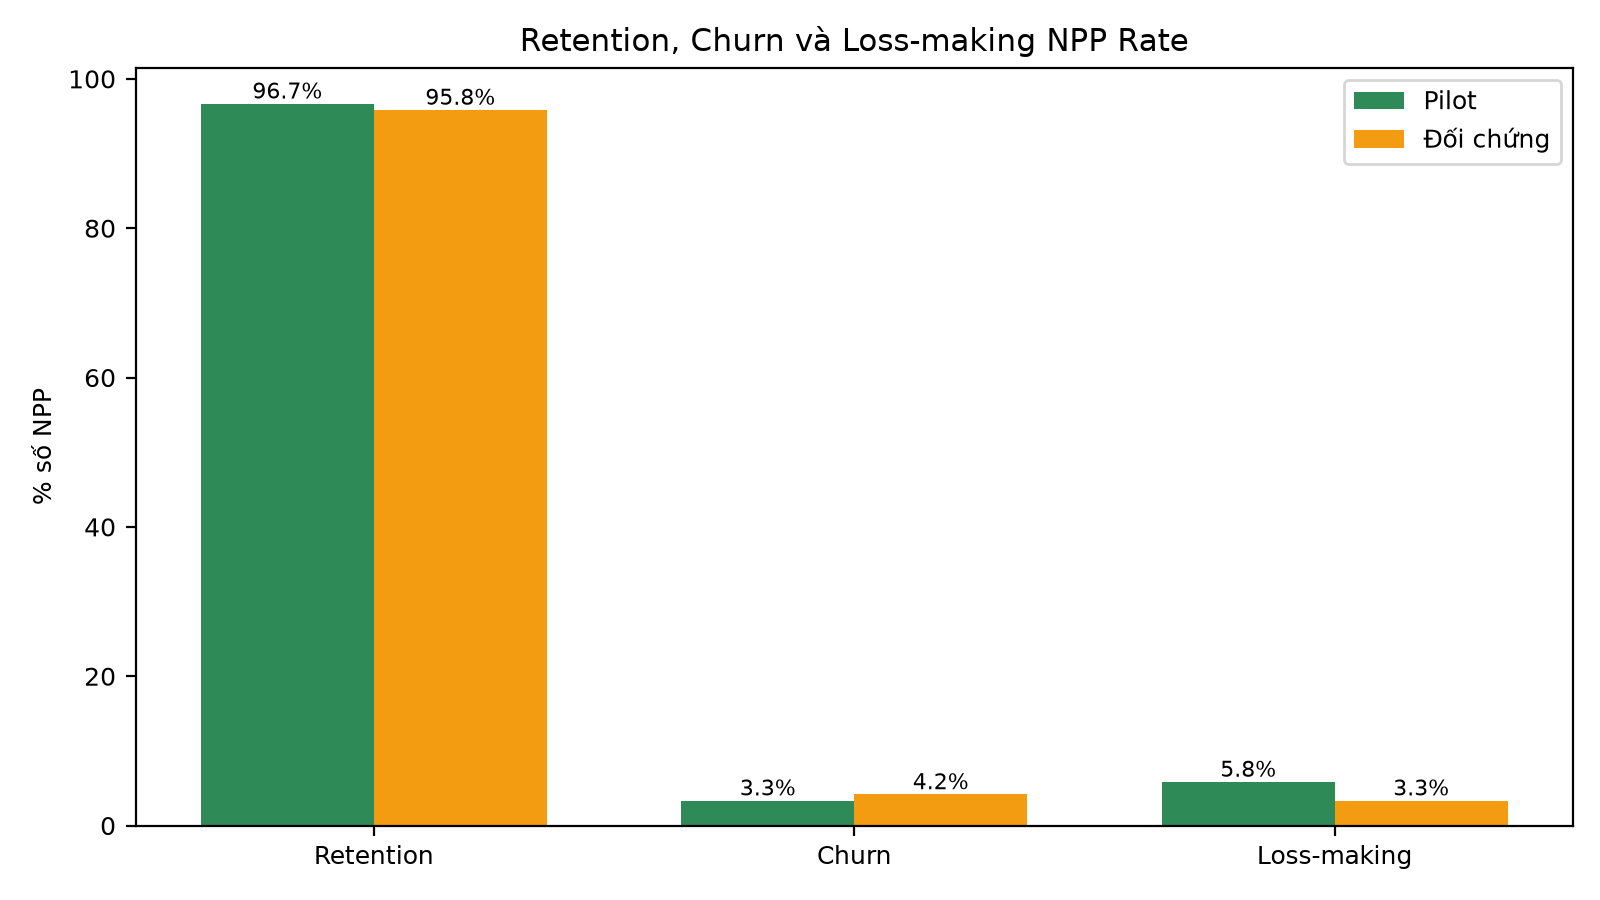

roi.png


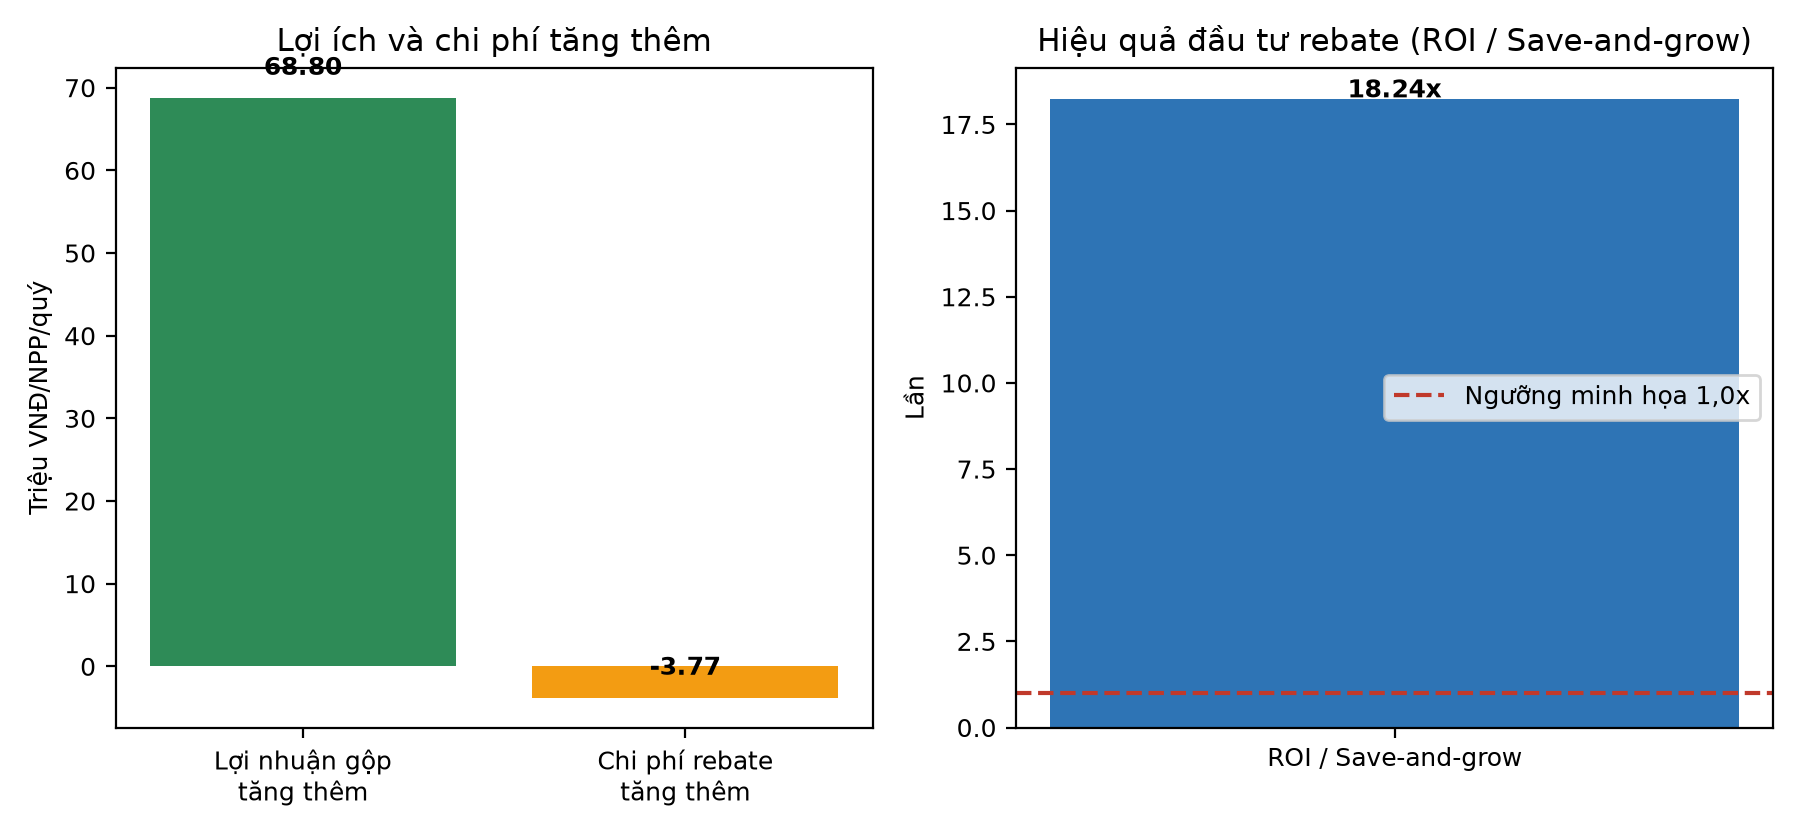

In [34]:
print("\n=== BIỂU ĐỒ ===")
chart_files = []
if "CHART_DIR" in globals() and CHART_DIR.exists():
    chart_files = sorted(
        p for p in CHART_DIR.iterdir()
        if p.suffix.lower() in {".png", ".jpg", ".jpeg"}
    )

if chart_files:
    for file in chart_files:
        print(file.name)
        display(Image(filename=str(file)))
else:
    print("Chưa tìm thấy ảnh biểu đồ trong CHART_DIR.")
    print("Trong từng cell vẽ biểu đồ, hãy lưu hình bằng fig.savefig(...).")

## Bước 6 - Kiểm tra dữ liệu và kết quả


In [ ]:
# BƯỚC 6 - Kiểm tra dữ liệu và kết quả
required = {"NPP_ID","Nhom_thu_nghiem","Ky","San_luong_tan","Net_Contribution_sau_rebate_VND","Rebate_thuc_chi_VND","Profitability_Gap_pct","Share_of_Wallet_pct","Active_Flag","Loss_Making_Flag","Ngan_sach_rebate_duyet_VND"}
missing = sorted(required - set(panel.columns))
assert not missing, f"Thiếu cột bắt buộc: {missing}"
assert set(panel["Ky"].dropna().unique()) >= {"Q2_2026","Q3_2026"}, "Cần có cả Q2_2026 và Q3_2026"
assert set(panel["Nhom_thu_nghiem"].dropna().unique()) >= {"Pilot","Đối chứng"}, "Cần có cả Pilot và Đối chứng"
print("Kiểm tra dữ liệu: OK")
print("Số NPP:", panel.NPP_ID.nunique())
display(bang_KPI)
